# PMRT multi-task v3 — with 60-s temporal context (CAP Sleep Database)

**Per 5-s window — unchanged, exactly the reference method (Fig. 2, all 8 feature boxes = Fig. 4):**
- network 1: Phy-SE-ResNet for EEG · network 2: Phy-SE-ResNet for EMG
- network 3: TFPN — 3 Cross-Modal Fusion blocks (Fig. 5) on stages 2/3/4 of both branches → FPN (Fig. 6)

**New in v3 — temporal context module:** 12 consecutive windows (60 s) are encoded by PMRT one by one; a small
Transformer shares information between them; every MLP head of every diamond receives
[its own FP-level features, temporal context]. Motivation: RMSSD is defined on 60 s and could not be estimated from 5 s alone (v2 result).

| Diamond | Output | Role |
|---|---|---|
| 1 | HR (bpm) | stress marker (main task) |
| 2 | RMSSD (ms) | stress marker (main task) |
| 3 | disorder, 6 classes | secondary task |
| 4 | sleep stage | auxiliary task |

Everything else as in v2: same folds, ln(RMSSD) + Huber, EMA, two checkpoints, early stopping after 15 epochs.

**Checkpoints:** after a session restart run all cells again — finished folds are skipped, an interrupted fold resumes.
Run the `flush_and_unmount` cell **only at the very end**.

## 1. Settings

In [ ]:
# Settings
ROOT = "/content/drive/MyDrive/sleep_project"
RUN_NAME = "pmrt_mt3_cv5"
N_FOLDS = 5
SEQ_LEN = 12
EPOCHS, PATIENCE, MIN_EPOCHS = 60, 12, 15
BATCH_SEQ, LR, WD = 24, 5e-4, 0.05
PER_SUBJECT = 1500
USE_AUG = True
USE_STAGE_HEAD = True
EMA_DECAY = 0.999
SEED = 42

## 2. Connect Google Drive

In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")
import sys, json, importlib, numpy as np, pandas as pd, torch
from pathlib import Path
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "- WARNING: no GPU")

Mounted at /content/drive
device: cpu - WARNING: no GPU


## 3. Model module (written to Drive)

In [ ]:
%%writefile /content/drive/MyDrive/sleep_project/pmrt_mt3.py
# Model module (written to Drive)
import json, glob, time, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path

VERSION = "mt3"
REG = ["hr", "rmssd"]
DISORDERS = ["Healthy", "NFLE", "RBD", "PLM", "Insomnia", "Narcolepsy"]
STAGES = ["N1", "N2", "N3", "REM"]
IGNORE = -100

def build_cache(npz_dir, cache_dir, tmp_dir="/content/_cache_tmp"):
    import shutil
    final = Path(cache_dir)
    if (final / "index.csv").exists():
        return
    cache = Path(tmp_dir); shutil.rmtree(cache, ignore_errors=True); cache.mkdir(parents=True, exist_ok=True)
    files = sorted(glob.glob(f"{npz_dir}/*.npz"))
    metas, n = [], 0
    for f in files:
        with np.load(f) as d:
            metas.append((f, json.loads(str(d["meta"])), len(d["hr"]))); n += len(d["hr"])
    X = np.lib.format.open_memmap(cache / "x.npy", mode="w+", dtype=np.float16, shape=(n, 2, 625))
    rows, pos = [], 0
    for f, m, k in metas:
        with np.load(f) as d:
            X[pos:pos + k, 0] = d["eeg"]; X[pos:pos + k, 1] = d["emg"]
            clip = (d["eeg_clip"].astype(np.float32) > 0.01) | (d["emg_clip"].astype(np.float32) > 0.01)
            rows.append(pd.DataFrame({"record": m["record"], "group": m["group"], "age": m["age"], "sex": m["sex"],
                                      "stage": d["stage"], "t": d["t"], "hr": d["hr"], "rmssd": d["rmssd"],
                                      "clipped": clip}))
        pos += k
        print(f"cached {m['record']:8s} {pos:,}/{n:,}", flush=True)
    X.flush(); del X
    pd.concat(rows, ignore_index=True).to_csv(cache / "index.csv", index=False)
    final.mkdir(parents=True, exist_ok=True)
    shutil.copy(cache / "x.npy", final / "x.npy"); shutil.copy(cache / "index.csv", final / "index.csv")
    shutil.rmtree(cache, ignore_errors=True)

def load_data(cache_dir):
    X = np.load(Path(cache_dir) / "x.npy")
    idx = pd.read_csv(Path(cache_dir) / "index.csv")
    idx["dis"] = idx.group.map({g: i for i, g in enumerate(DISORDERS)}).fillna(IGNORE).astype(int)
    idx["stg"] = idx.stage.map({s: i for i, s in enumerate(STAGES)}).astype(int)
    return X, idx

def make_folds(idx, k=5, seed=42):
    rng = np.random.default_rng(seed); fold, start = {}, 0
    for g, recs in sorted(idx.groupby("group").record.unique().items()):
        recs = sorted(recs); rng.shuffle(recs)
        for i, r in enumerate(recs):
            fold[r] = int((start + i) % k)
        start += len(recs)
    return fold

def fold_rows(idx, fold, k_test, k=5):
    f = idx.record.map(fold).to_numpy()
    k_val = (k_test + 1) % k
    return {"train": np.where((f != k_test) & (f != k_val))[0],
            "val": np.where(f == k_val)[0], "test": np.where(f == k_test)[0]}

class SubjectBalancedBatches:
    def __init__(self, X, Y, rows, rec, batch, device, per_subject=1500, shuffle=True):
        self.X, self.Y, self.b, self.dev, self.k, self.sh = X, Y, batch, device, per_subject, shuffle
        self.groups = [rows[rec[rows] == r] for r in np.unique(rec[rows])] if shuffle else None
        self.rows = rows
    def _epoch_rows(self):
        if not self.sh: return self.rows
        pick = [g if len(g) <= self.k else np.random.choice(g, self.k, replace=False) for g in self.groups]
        return np.random.permutation(np.concatenate(pick))
    def __len__(self):
        n = sum(min(len(g), self.k) for g in self.groups) if self.sh else len(self.rows)
        return math.ceil(n / self.b)
    def __iter__(self):
        r = self._epoch_rows()
        for i in range(0, len(r), self.b):
            j = np.sort(r[i:i + self.b])
            x = torch.from_numpy(np.asarray(self.X[j], dtype=np.float32)).to(self.dev, non_blocking=True)
            y = {k: torch.from_numpy(v[j]).to(self.dev, non_blocking=True) for k, v in self.Y.items()}
            yield x, y, j

def augment(x):
    B = x.shape[0]; dev = x.device
    x = x * torch.empty(B, 2, 1, device=dev).uniform_(0.8, 1.2)
    x = x * torch.where(torch.rand(B, 2, 1, device=dev) < 0.5, -1.0, 1.0)
    x = x + 0.05 * torch.randn_like(x)
    L = x.shape[-1]; m = torch.rand(B, device=dev) < 0.3
    if m.any():
        s = torch.randint(0, L - 50, (B,), device=dev); w = torch.randint(10, 50, (B,), device=dev)
        t = torch.arange(L, device=dev)[None]
        mask = (t >= s[:, None]) & (t < (s + w)[:, None]) & m[:, None]
        x = x.masked_fill(mask[:, None, :], 0.0)
    drop = torch.rand(B, device=dev) < 0.1
    if drop.any():
        ch = torch.randint(0, 2, (B,), device=dev)
        keep = torch.ones(B, 2, 1, device=dev)
        keep[drop, ch[drop], 0] = 0.0
        x = x * keep
    return x

class StemBlock(nn.Module):
    def __init__(self, c_out=64):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(1, c_out, 7, 2, 3, bias=False), nn.BatchNorm1d(c_out), nn.ReLU(inplace=True),
                                 nn.MaxPool1d(3, 2, 1))
    def forward(self, x): return self.net(x)

class PhySEResidualBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=2, deriv_kernel=15, r=16, lam=1.0):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv1d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm1d(c_out), nn.ReLU(inplace=True),
            nn.Conv1d(c_out, c_out, 3, 1, 1, bias=False), nn.BatchNorm1d(c_out))
        self.deriv = nn.Sequential(
            nn.Conv1d(c_in, c_out, deriv_kernel, stride, deriv_kernel // 2, bias=False), nn.BatchNorm1d(c_out), nn.Hardtanh())
        self.lam = nn.Parameter(torch.tensor(float(lam)))
        h = max(c_out // r, 4)
        self.ub, self.ua = nn.Linear(c_out, h), nn.Linear(h, 2 * c_out)
        self.short = (nn.Identity() if (c_in == c_out and stride == 1) else
                      nn.Sequential(nn.Conv1d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm1d(c_out)))
        self.act = nn.ReLU(inplace=True)
    def forward(self, x):
        fm = self.main(x); fd = self.deriv(x) * self.lam
        a = self.ua(F.relu(self.ub(fm.mean(-1))))
        a = torch.softmax(a.view(-1, 2, fm.shape[1]), dim=1).unsqueeze(-1)
        return self.act(a[:, 0] * fm + a[:, 1] * fd + self.short(x))

class PhySEResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256, 512), **kw):
        super().__init__()
        self.stem = StemBlock(widths[0])
        c, st = widths[0], []
        for w in widths: st.append(PhySEResidualBlock(c, w, stride=2, **kw)); c = w
        self.stages = nn.ModuleList(st)
    def forward(self, x):
        x, feats = self.stem(x), []
        for s in self.stages: x = s(x); feats.append(x)
        return feats

class CrossModalFusion(nn.Module):
    def __init__(self, c_in, d=128, r=16):
        super().__init__()
        self.pa = nn.Sequential(nn.Conv1d(c_in, d, 1, bias=False), nn.BatchNorm1d(d))
        self.pb = nn.Sequential(nn.Conv1d(c_in, d, 1, bias=False), nn.BatchNorm1d(d))
        self.cat = nn.Conv1d(2 * d, d, 1)
        self.gate = nn.Sequential(nn.Flatten(), nn.Linear(2 * d, 2 * d // r), nn.ReLU(inplace=True), nn.Linear(2 * d // r, 3 * d))
        self.s = nn.Conv1d(d, 1, 1); self.off = nn.Conv1d(d, d, 3, 1, 1)
        self.enh = nn.Sequential(nn.Conv1d(d, d, 3, 1, 1, groups=d, bias=False), nn.BatchNorm1d(d), nn.ReLU(inplace=True))
        self.d = d
    def forward(self, fa, fb):
        a, b = self.pa(fa), self.pb(fb); c = torch.cat([a, b], 1)
        w = torch.softmax(self.gate(c.mean(-1, keepdim=True)).view(-1, 3, self.d), dim=1).unsqueeze(-1)
        f = w[:, 0] * (a + b) + w[:, 1] * (a * b) + w[:, 2] * self.cat(c)
        f = self.off(torch.sigmoid(self.s(f)) * f) + f
        return self.enh(f)

def make_sequences(idx, rows, L=12, max_gap=60.0, offset=0):
    sub = idx.iloc[rows][["record", "t"]].assign(row=rows).sort_values(["record", "t"])
    seqs = []
    for _, g in sub.groupby("record", sort=False):
        r, t = g.row.to_numpy(), g.t.to_numpy()
        breaks = np.where(np.diff(t) > max_gap)[0] + 1
        for seg in np.split(r, breaks):
            o = offset % L if len(seg) > L else 0
            cuts = list(range(o, len(seg), L)) if o else list(range(0, len(seg), L))
            if o: cuts = [0] + cuts
            for a, b in zip(cuts, cuts[1:] + [len(seg)]):
                chunk = seg[a:b]
                if len(chunk): seqs.append(np.pad(chunk, (0, L - len(chunk)), constant_values=-1))
    return np.array(seqs, dtype=np.int64).reshape(-1, L)

class SequenceBatches:
    def __init__(self, X, Y, idx, rows, batch_seq, device, L=12, per_subject=1500, train=True):
        self.X, self.Y, self.idx, self.rows, self.b, self.dev, self.L = X, Y, idx, rows, batch_seq, device, L
        self.k, self.train = per_subject // L, train
        self.rec = idx.record.to_numpy()
        self.fixed = None if train else make_sequences(idx, rows, L)
    def _epoch(self):
        if not self.train: return self.fixed
        s = make_sequences(self.idx, self.rows, self.L, offset=np.random.randint(self.L))
        own = self.rec[s[:, 0]]
        keep = np.concatenate([np.random.permutation(np.where(own == r)[0])[:self.k] for r in np.unique(own)])
        return s[np.random.permutation(keep)]
    def __len__(self):
        n = len(self.fixed) if not self.train else len(np.unique(self.rec[self.rows])) * self.k
        return math.ceil(n / self.b)
    def __iter__(self):
        S = self._epoch()
        for i in range(0, len(S), self.b):
            s = S[i:i + self.b]; m = s >= 0
            j = s[m]
            x = torch.from_numpy(np.asarray(self.X[j], dtype=np.float32)).to(self.dev, non_blocking=True)
            y = {k: torch.from_numpy(v[j]).to(self.dev, non_blocking=True) for k, v in self.Y.items()}
            yield x, torch.from_numpy(m).to(self.dev), y, j

class MLPHead(nn.Module):
    def __init__(self, d, ctx, out, hidden=64, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d + ctx, hidden), nn.ELU(), nn.Dropout(p), nn.Linear(hidden, out))
    def forward(self, f, c): return self.net(torch.cat([f.mean(-1), c], 1))

class MultiScalePredictor(nn.Module):
    def __init__(self, d, ctx, out, levels=3, p=0.3):
        super().__init__()
        self.heads = nn.ModuleList([MLPHead(d, ctx, out, p=p) for _ in range(levels)])
        self.alpha = nn.Parameter(torch.zeros(levels))
    def forward(self, feats, c):
        w = torch.softmax(self.alpha, 0)
        return sum(w[i] * h(f, c) for i, (h, f) in enumerate(zip(self.heads, feats)))

class TemporalContext(nn.Module):
    def __init__(self, d=128, L=12, layers=2, heads=4, p=0.1):
        super().__init__()
        self.proj = nn.Linear(3 * d, d); self.pos = nn.Parameter(torch.zeros(1, L, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, p, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
    def forward(self, v, mask):
        h = self.proj(v) + self.pos[:, :v.shape[1]]
        return self.enc(h, src_key_padding_mask=~mask)

class PMRTTemporal(nn.Module):
    def __init__(self, d=128, L=12, deriv_kernel=15, r=16, p=0.3, feat_drop=0.1, stage_head=True):
        super().__init__()
        self.branch_eeg = PhySEResNet(deriv_kernel=deriv_kernel, r=r)
        self.branch_emg = PhySEResNet(deriv_kernel=deriv_kernel, r=r)
        self.fusion = nn.ModuleList([CrossModalFusion(c, d, r) for c in (128, 256, 512)])
        self.fdrop = nn.Dropout1d(feat_drop)
        self.context = TemporalContext(d, L)
        outs = {"hr": 1, "rmssd": 1, "dis": len(DISORDERS)}
        if stage_head: outs["stg"] = len(STAGES)
        self.pred = nn.ModuleDict({k: MultiScalePredictor(d, d, o, p=p) for k, o in outs.items()})
    def windows(self, x):
        fa = self.branch_eeg(x[:, :1])[1:]; fb = self.branch_emg(x[:, 1:])[1:]
        m = [fu(a, b) for fu, a, b in zip(self.fusion, fa, fb)]
        p3 = m[2]
        p2 = m[1] + F.interpolate(p3, size=m[1].shape[-1], mode="nearest")
        p1 = m[0] + F.interpolate(p2, size=m[0].shape[-1], mode="nearest")
        return [self.fdrop(q) for q in (p1, p2, p3)]
    def forward(self, x, mask):
        fp = self.windows(x)
        v = torch.cat([q.mean(-1) for q in fp], 1)
        V = v.new_zeros(*mask.shape, v.shape[1]); V[mask] = v
        c = self.context(V, mask)[mask]
        out = {k: p(fp, c) for k, p in self.pred.items()}
        out["hr"], out["rmssd"] = out["hr"][:, 0], out["rmssd"][:, 0]
        return out

class Targets:
    def __init__(self, idx, train_rows):
        self.raw = idx[REG].to_numpy(np.float64)
        t = self._fwd(self.raw)
        self.mu, self.sd = t[train_rows].mean(0), t[train_rows].std(0)
        self.raw_sd = self.raw[train_rows].std(0)
    @staticmethod
    def _fwd(raw): return np.stack([raw[:, 0], np.log(np.maximum(raw[:, 1], 1.0))], 1)
    def encode(self): return ((self._fwd(self.raw) - self.mu) / self.sd).astype(np.float32)
    def decode(self, hr_z, rm_z):
        return hr_z * self.sd[0] + self.mu[0], np.exp(rm_z * self.sd[1] + self.mu[1])

class MultiTaskLoss:
    def __init__(self, idx_train, device, w_dis=0.5, w_stg=0.3, smoothing=0.1):
        subj = idx_train.drop_duplicates("record")
        n_dis = np.array([(subj.dis == i).sum() for i in range(len(DISORDERS))], float)
        w = 1.0 / np.maximum(n_dis, 1); w = w / w.sum() * len(w)
        n_stg = np.array([(idx_train.stg == i).sum() for i in range(len(STAGES))], float)
        ws = 1.0 / np.sqrt(np.maximum(n_stg, 1)); ws = ws / ws.sum() * len(ws)
        self.ce_dis = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device),
                                          ignore_index=IGNORE, label_smoothing=smoothing)
        self.ce_stg = nn.CrossEntropyLoss(weight=torch.tensor(ws, dtype=torch.float32, device=device),
                                          label_smoothing=smoothing)
        self.w_dis, self.w_stg = w_dis, w_stg
    def __call__(self, out, y):
        hub = lambda a, b: F.smooth_l1_loss(a.float(), b, beta=1.0)
        parts = {"hr": hub(out["hr"], y["hr"]), "rmssd": hub(out["rmssd"], y["rmssd"])}
        if (y["dis"] != IGNORE).any(): parts["dis"] = self.ce_dis(out["dis"].float(), y["dis"])
        else: parts["dis"] = torch.zeros((), device=y["hr"].device)
        total = parts["hr"] + parts["rmssd"] + self.w_dis * parts["dis"]
        if "stg" in out:
            parts["stg"] = self.ce_stg(out["stg"].float(), y["stg"]); total = total + self.w_stg * parts["stg"]
        return total, parts

class EMA:
    def __init__(self, model, decay=0.999):
        import copy
        self.m = copy.deepcopy(model).eval(); self.d = decay
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        for e, p in zip(self.m.parameters(), model.parameters()): e.mul_(self.d).add_(p.detach(), alpha=1 - self.d)
        for e, b in zip(self.m.buffers(), model.buffers()): e.copy_(b)

@torch.no_grad()
def predict(model, loader):
    model.eval(); res, J = {}, []
    for x, mask, _, j in loader:
        with torch.autocast(x.device.type, dtype=torch.float16, enabled=x.device.type == "cuda"):
            out = model(x, mask)
        for k, v in out.items():
            v = v.float()
            res.setdefault(k, []).append((torch.softmax(v, -1) if v.ndim == 2 else v).cpu().numpy())
        J.append(j)
    J = np.concatenate(J); o = np.argsort(J, kind="stable")
    return J[o], {k: np.concatenate(v)[o] for k, v in res.items()}

def reg_metrics(y, p):
    e = p - y
    return {"MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e ** 2))), "ME": float(np.mean(e)),
            "SD": float(np.std(e)), "r": float(np.corrcoef(y, p)[0, 1]),
            "R2": float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2))}

def val_scores(p, j, tg, dis, stg, rec):
    hr, rm = tg.decode(p["hr"], p["rmssd"])
    hr_mae = float(np.mean(np.abs(hr - tg.raw[j, 0]))); rm_mae = float(np.mean(np.abs(rm - tg.raw[j, 1])))
    s = {"stress_score": hr_mae / tg.raw_sd[0] + rm_mae / tg.raw_sd[1], "hr_MAE": hr_mae, "rmssd_MAE": rm_mae}
    d = pd.DataFrame(p["dis"], columns=DISORDERS); d["rec"] = rec[j]; d["y"] = dis[j]
    d = d[d.y != IGNORE].groupby("rec").agg({**{c: "mean" for c in DISORDERS}, "y": "first"})
    if len(d):
        pr = d[DISORDERS].to_numpy()
        s["dis_subject_loss"] = float(-np.mean(np.log(pr[np.arange(len(d)), d.y.to_numpy()] + 1e-8)))
        s["dis_subject_acc"] = float(np.mean(pr.argmax(1) == d.y.to_numpy()))
    else:
        s["dis_subject_loss"], s["dis_subject_acc"] = float("nan"), float("nan")
    if "stg" in p: s["stage_acc"] = float(np.mean(p["stg"].argmax(1) == stg[j]))
    return s

def train_fold(model, tr, va, loss_fn, tg, dis, stg, rec, run_dir, epochs=60, lr=5e-4, wd=0.05,
               patience=12, min_epochs=15, use_aug=True, ema_decay=0.999):
    run = Path(run_dir); run.mkdir(parents=True, exist_ok=True)
    dev = next(model.parameters()).device
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs, steps_per_epoch=len(tr),
                                                pct_start=max(0.1, 3 / (epochs * len(tr))))
    scaler = torch.amp.GradScaler(enabled=dev.type == "cuda")
    ema = EMA(model, ema_decay)
    state = {"epoch": 0, "best_stress": float("inf"), "best_dis": float("inf"), "bad": 0, "history": []}
    if (run / "last.pt").exists():
        ck = torch.load(run / "last.pt", map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"]); ema.m.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"]); state = ck["state"]
        print(f"  resumed after epoch {state['epoch']}")
    while state["epoch"] < epochs and not (state["epoch"] >= min_epochs and state["bad"] >= patience):
        ep = state["epoch"] + 1; t0 = time.time(); model.train(); tot, nb = 0.0, 0
        for step, (x, mask, y, _) in enumerate(tr):
            if step >= len(tr): break
            if use_aug: x = augment(x)
            with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
                out = model(x, mask)
            loss, _ = loss_fn(out, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
            tot += loss.item(); nb += 1
        j, p = predict(ema.m, va)
        s = val_scores(p, j, tg, dis, stg, rec)
        rec_h = {"epoch": ep, "train_loss": tot / nb, **{f"val_{k}": v for k, v in s.items()},
                 "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0}
        state["history"].append(rec_h); state["epoch"] = ep
        flag, improved = "", False
        if s["stress_score"] < state["best_stress"]:
            state["best_stress"] = s["stress_score"]; improved = True; flag += " *stress*"
            torch.save({"model": ema.m.state_dict(), "epoch": ep}, run / "best_stress.pt")
        if s["dis_subject_loss"] < state["best_dis"]:
            state["best_dis"] = s["dis_subject_loss"]; improved = True; flag += " *dis*"
            torch.save({"model": ema.m.state_dict(), "epoch": ep}, run / "best_dis.pt")
        state["bad"] = 0 if improved else state["bad"] + 1
        torch.save({"model": model.state_dict(), "ema": ema.m.state_dict(), "opt": opt.state_dict(),
                    "sched": sched.state_dict(), "scaler": scaler.state_dict(), "state": state}, run / "last.pt")
        pd.DataFrame(state["history"]).to_csv(run / "history.csv", index=False)
        print(f"  ep {ep:3d} | train {rec_h['train_loss']:.3f} | stress score {s['stress_score']:.3f} | HR MAE {s['hr_MAE']:.2f} | "
              f"RMSSD MAE {s['rmssd_MAE']:.1f} | dis subj acc {s['dis_subject_acc']:.2f} loss {s['dis_subject_loss']:.2f}" +
              (f" | stage acc {s['stage_acc']:.2f}" if "stage_acc" in s else "") + f" | {rec_h['sec']:.0f}s{flag}", flush=True)
    h = pd.DataFrame(state["history"])
    print(f"  finished after {state['epoch']} epochs | best stress epoch {int(h.loc[h.val_stress_score.idxmin(), 'epoch'])} "
          f"| best disorder epoch {int(h.loc[h.val_dis_subject_loss.idxmin(), 'epoch'])}")


Overwriting /content/drive/MyDrive/sleep_project/pmrt_mt3.py


## 4. Load module

In [ ]:
# Load module
sys.path.insert(0, ROOT)
import pmrt_mt3 as M
importlib.reload(M)
print("pmrt_mt3", M.VERSION, "loaded")

pmrt_mt3 mt3 loaded


## 5. Data and subject-wise folds (same folds as v1/v2)

In [ ]:
# Data and subject-wise folds (same folds as v1/v2)
CACHE = Path(ROOT) / "cap_dataset_cache"
M.build_cache(str(Path(ROOT) / "cap_processed"), str(CACHE))
X, idx = M.load_data(str(CACHE))
REC = idx.record.to_numpy()

fold_file = Path(ROOT) / f"folds_{N_FOLDS}.json"
if not fold_file.exists():
    fold_file.write_text(json.dumps(M.make_folds(idx, N_FOLDS, SEED), indent=1))
FOLD = json.loads(fold_file.read_text())

subj = idx.drop_duplicates("record").assign(fold=lambda d: d.record.map(FOLD))
print("windows:", X.shape, "| subjects:", len(subj))
print(pd.crosstab(subj.group, subj.fold, margins=True).to_string())

windows: (483170, 2, 625) | subjects: 103
fold         0   1   2   3   4  All
group                              
Bruxism      1   1   0   0   0    2
Healthy      2   2   3   3   3   13
Insomnia     2   2   2   2   1    9
NFLE         8   8   7   7   8   38
Narcolepsy   1   1   1   1   1    5
PLM          2   2   2   2   2   10
RBD          4   4   5   5   4   22
SDB          1   1   1   0   1    4
All         21  21  21  20  20  103


## 6. Model check

In [ ]:
# Model check
model = M.PMRTTemporal(L=SEQ_LEN, stage_head=USE_STAGE_HEAD).to(DEV)
print("parameters: %.2f M" % (sum(p.numel() for p in model.parameters()) / 1e6))
print("diamonds:", list(model.pred.keys()), "| MLPs:", 3 * len(model.pred))
mask = torch.ones(2, SEQ_LEN, dtype=torch.bool, device=DEV); mask[1, 8:] = False
with torch.no_grad():
    model.eval(); out = model(torch.randn(int(mask.sum()), 2, 625, device=DEV), mask)
print({k: tuple(v.shape) for k, v in out.items()}, "(one output per real window)")
del model

parameters: 9.96 M
diamonds: ['hr', 'rmssd', 'dis', 'stg'] | MLPs: 12
{'hr': (20,), 'rmssd': (20,), 'dis': (20, 6), 'stg': (20, 4)} (one output per real window)


## 7. Training — 5 folds (checkpoint after every epoch)

In [ ]:
# Training — 5 folds (checkpoint after every epoch)
RUN = Path(ROOT) / "runs" / RUN_NAME
RUN.mkdir(parents=True, exist_ok=True)
(RUN / "config.json").write_text(json.dumps({k: globals()[k] for k in
    ["N_FOLDS", "SEQ_LEN", "EPOCHS", "PATIENCE", "MIN_EPOCHS", "BATCH_SEQ", "LR", "WD", "PER_SUBJECT", "USE_AUG",
     "USE_STAGE_HEAD", "EMA_DECAY", "SEED"]} | {"version": M.VERSION}, indent=1))
DIS, STG = idx.dis.to_numpy(np.int64), idx.stg.to_numpy(np.int64)

for k in range(N_FOLDS):
    fdir = RUN / f"fold{k}"
    if (fdir / "test_pred.csv").exists():
        print(f"fold {k}: already finished - skipped"); continue
    torch.manual_seed(SEED + k); np.random.seed(SEED + k)
    rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
    tg = M.Targets(idx, rows["train"])
    yz = tg.encode()
    Y = {"hr": yz[:, 0], "rmssd": yz[:, 1], "dis": DIS, "stg": STG}
    tr = M.SequenceBatches(X, Y, idx, rows["train"], BATCH_SEQ, DEV, SEQ_LEN, PER_SUBJECT, train=True)
    va = M.SequenceBatches(X, Y, idx, rows["val"], 64, DEV, SEQ_LEN, train=False)
    te = M.SequenceBatches(X, Y, idx, rows["test"], 64, DEV, SEQ_LEN, train=False)
    print(f"\n===== fold {k} | train {len(np.unique(REC[rows['train']]))} subj | val {len(np.unique(REC[rows['val']]))} "
          f"| test {len(np.unique(REC[rows['test']]))} =====")
    loss_fn = M.MultiTaskLoss(idx.iloc[rows["train"]], DEV)
    model = M.PMRTTemporal(L=SEQ_LEN, stage_head=USE_STAGE_HEAD).to(DEV)
    M.train_fold(model, tr, va, loss_fn, tg, DIS, STG, REC, fdir, epochs=EPOCHS, lr=LR, wd=WD,
                 patience=PATIENCE, min_epochs=MIN_EPOCHS, use_aug=USE_AUG, ema_decay=EMA_DECAY)

    model.load_state_dict(torch.load(fdir / "best_stress.pt", map_location=DEV, weights_only=False)["model"])
    j, p = M.predict(model, te)
    model.load_state_dict(torch.load(fdir / "best_dis.pt", map_location=DEV, weights_only=False)["model"])
    j2, p2 = M.predict(model, te)
    assert (j == j2).all() and (j == np.sort(rows["test"])).all()
    out = idx.iloc[j][["record", "group", "stage", "clipped", "dis", "stg"] + M.REG].reset_index(drop=True)
    out["fold"] = k
    out["hr_pred"], out["rmssd_pred"] = tg.decode(p["hr"], p["rmssd"])
    for c, name in enumerate(M.DISORDERS): out[f"p_{name}"] = p2["dis"][:, c]
    if "stg" in p:
        for c, name in enumerate(M.STAGES): out[f"p_{name}"] = p["stg"][:, c]
    out["mu_hr"], out["mu_rmssd"] = np.median(tg.raw[rows["train"]], 0)
    out.to_csv(fdir / "test_pred.csv", index=False)
    print(f"fold {k} saved")
print("\nall folds finished")


===== fold 0 | train 61 subj | val 21 | test 21 =====
  ep   1 | train 2.131 | stress score 1.597 | HR MAE 7.52 | RMSSD MAE 26.1 | dis subj acc 0.16 loss 1.79 | stage acc 0.37 | 86s *stress* *dis*
  ep   2 | train 1.799 | stress score 1.611 | HR MAE 7.66 | RMSSD MAE 26.1 | dis subj acc 0.11 loss 1.80 | stage acc 0.58 | 77s
  ep   3 | train 1.588 | stress score 1.580 | HR MAE 7.29 | RMSSD MAE 26.4 | dis subj acc 0.21 loss 1.70 | stage acc 0.65 | 76s *stress* *dis*
  ep   4 | train 1.460 | stress score 1.549 | HR MAE 6.95 | RMSSD MAE 26.6 | dis subj acc 0.16 loss 1.81 | stage acc 0.71 | 76s *stress*
  ep   5 | train 1.387 | stress score 1.559 | HR MAE 6.90 | RMSSD MAE 27.1 | dis subj acc 0.11 loss 1.93 | stage acc 0.68 | 78s
  ep   6 | train 1.303 | stress score 1.588 | HR MAE 6.85 | RMSSD MAE 28.3 | dis subj acc 0.11 loss 1.80 | stage acc 0.72 | 76s
  ep   7 | train 1.242 | stress score 1.504 | HR MAE 6.28 | RMSSD MAE 27.5 | dis subj acc 0.16 loss 1.90 | stage acc 0.69 | 76s *stress*
 

## 8. Training curves

fold 0: epochs 60 | best stress epoch 54 (HR MAE 3.28, RMSSD MAE 25.7) | best disorder epoch 40 (subject acc 0.63)
fold 1: epochs 48 | best stress epoch 18 (HR MAE 4.41, RMSSD MAE 31.9) | best disorder epoch 36 (subject acc 0.55)
fold 2: epochs 39 | best stress epoch 19 (HR MAE 3.58, RMSSD MAE 20.4) | best disorder epoch 27 (subject acc 0.45)
fold 3: epochs 60 | best stress epoch 18 (HR MAE 4.00, RMSSD MAE 26.3) | best disorder epoch 50 (subject acc 0.63)
fold 4: epochs 42 | best stress epoch 21 (HR MAE 5.59, RMSSD MAE 29.4) | best disorder epoch 30 (subject acc 0.63)


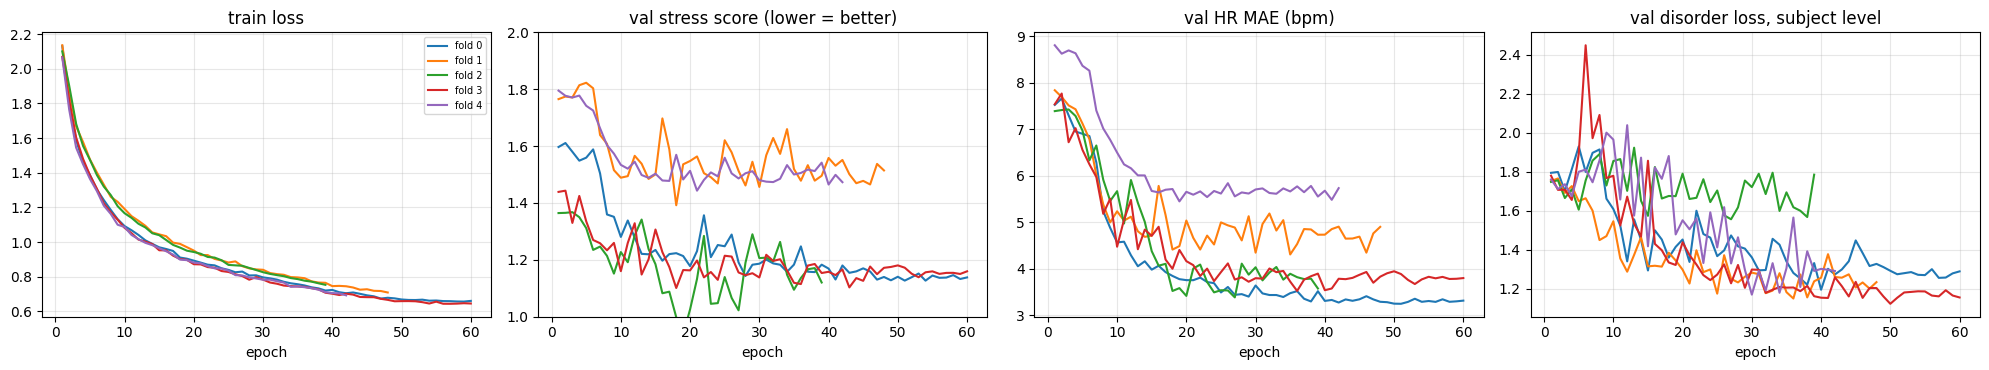

In [ ]:
# Training curves
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for k in range(N_FOLDS):
    f = RUN / f"fold{k}" / "history.csv"
    if not f.exists(): continue
    h = pd.read_csv(f)
    ax[0].plot(h.epoch, h.train_loss, f"C{k}", label=f"fold {k}")
    ax[1].plot(h.epoch, h.val_stress_score, f"C{k}")
    ax[2].plot(h.epoch, h.val_hr_MAE, f"C{k}")
    ax[3].plot(h.epoch, h.val_dis_subject_loss, f"C{k}")
    bs, bd = h.loc[h.val_stress_score.idxmin()], h.loc[h.val_dis_subject_loss.idxmin()]
    print(f"fold {k}: epochs {len(h)} | best stress epoch {int(bs.epoch)} (HR MAE {bs.val_hr_MAE:.2f}, RMSSD MAE "
          f"{bs.val_rmssd_MAE:.1f}) | best disorder epoch {int(bd.epoch)} (subject acc {bd.val_dis_subject_acc:.2f})")
ax[0].set_title("train loss"); ax[0].legend(fontsize=7)
ax[1].set_title("val stress score (lower = better)"); ax[1].set_ylim(1.0, 2.0)
ax[2].set_title("val HR MAE (bpm)")
ax[3].set_title("val disorder loss, subject level")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN / "training_curves.png", dpi=150); plt.show()

## 9. Final results on all subjects + comparison v1 / v2 / v3

In [ ]:
# Final results on all subjects + comparison v1 / v2 / v3
from sklearn.metrics import (balanced_accuracy_score, f1_score, confusion_matrix, cohen_kappa_score,
                             roc_auc_score, accuracy_score, recall_score)
pred = pd.concat([pd.read_csv(RUN / f"fold{k}" / "test_pred.csv") for k in range(N_FOLDS)], ignore_index=True)
print(f"test windows: {len(pred):,} | test subjects: {pred.record.nunique()} (every subject tested once)\n")

rows = []
def add(name, d):
    for t in M.REG:
        rows.append({"subset": name, "target": t, "n": len(d), **M.reg_metrics(d[t].to_numpy(), d[f"{t}_pred"].to_numpy())})
add("all", pred)
for t in M.REG:
    rows.append({"subset": "baseline (train median)", "target": t, "n": len(pred), "MAE": float(np.mean(np.abs(pred[t] - pred[f"mu_{t}"])))})
add("not clipped", pred[~pred.clipped]); add("clipped", pred[pred.clipped])
for g, d in pred.groupby("group"): add(f"group={g}", d)
for s, d in pred.groupby("stage"): add(f"stage={s}", d)
reg = pd.DataFrame(rows)
per_fold = pd.DataFrame([{"fold": k, "target": t, **M.reg_metrics(d[t].to_numpy(), d[f"{t}_pred"].to_numpy())}
                         for k, d in pred.groupby("fold") for t in M.REG])
print("1) STRESS MARKERS (regression)"); print(reg.round(3).to_string(index=False))
print("\n   mean ± std over folds:")
print(per_fold.groupby("target")[["MAE", "RMSE", "r"]].agg(["mean", "std"]).round(3).to_string())

def stress_index(d, hr, rm):
    g = d.groupby("record")
    z = lambda c: (d[c] - g[c].transform("mean")) / g[c].transform("std")
    return z(hr) - z(rm)
pred["si_true"] = stress_index(pred, "hr", "rmssd")
pred["si_pred"] = stress_index(pred, "hr_pred", "rmssd_pred")
pred["stress_true"] = (pred.si_true > 1.0).astype(int)
pred["stress_pred"] = (pred.si_pred > 1.0).astype(int)
st = {"prevalence": pred.stress_true.mean(), "AUC": roc_auc_score(pred.stress_true, pred.si_pred),
      "F1": f1_score(pred.stress_true, pred.stress_pred), "balanced_acc": balanced_accuracy_score(pred.stress_true, pred.stress_pred),
      "sensitivity": recall_score(pred.stress_true, pred.stress_pred), "specificity": recall_score(1 - pred.stress_true, 1 - pred.stress_pred)}
print("\n2) STRESS DETECTION (stress index = z(HR) - z(RMSSD) within subject > 1)")
print({k: round(float(v), 3) for k, v in st.items()})
print(pd.DataFrame([{"group": g, "AUC": roc_auc_score(d.stress_true, d.si_pred) if d.stress_true.nunique() > 1 else np.nan,
                     "F1": f1_score(d.stress_true, d.stress_pred)} for g, d in pred.groupby("group")]).round(3).to_string(index=False))

pcols = [f"p_{c}" for c in M.DISORDERS]
subj = pred.groupby("record").agg(group=("group", "first"), dis=("dis", "first"), **{c: (c, "mean") for c in pcols}).reset_index()
subj["pred_dis"] = subj[pcols].to_numpy().argmax(1)
s6 = subj[subj.dis != M.IGNORE]
print(f"\n3) DISORDER, 6 classes, subject level ({len(s6)} subjects)")
print({"balanced_acc": round(balanced_accuracy_score(s6.dis, s6.pred_dis), 3), "macro_F1": round(f1_score(s6.dis, s6.pred_dis, average="macro"), 3),
       "accuracy": round(accuracy_score(s6.dis, s6.pred_dis), 3), "chance (balanced)": round(1 / len(M.DISORDERS), 3)})
cm = pd.DataFrame(confusion_matrix(s6.dis, s6.pred_dis, labels=range(len(M.DISORDERS))), index=M.DISORDERS, columns=M.DISORDERS)
print("confusion matrix (rows = true, columns = predicted):"); print(cm.to_string())
print("recall per class:", dict(zip(M.DISORDERS, recall_score(s6.dis, s6.pred_dis, labels=range(len(M.DISORDERS)), average=None, zero_division=0).round(2).tolist())))
hb = (subj.group != "Healthy").astype(int)
print("healthy vs disorder (all", len(subj), "subjects):",
      {"AUC": round(roc_auc_score(hb, 1 - subj.p_Healthy), 3), "balanced_acc": round(balanced_accuracy_score(hb, (subj.pred_dis != 0).astype(int)), 3)})
print("SDB / Bruxism subjects were predicted as:", dict(zip(subj[subj.dis == M.IGNORE].record, [M.DISORDERS[i] for i in subj[subj.dis == M.IGNORE].pred_dis])))

if "p_N1" in pred:
    sp = pred[[f"p_{s}" for s in M.STAGES]].to_numpy().argmax(1)
    print(f"\n4) SLEEP STAGE (auxiliary), window level")
    print({"accuracy": round(accuracy_score(pred.stg, sp), 3), "kappa": round(cohen_kappa_score(pred.stg, sp), 3),
           "macro_F1": round(f1_score(pred.stg, sp, average="macro"), 3)})
    print(pd.DataFrame(confusion_matrix(pred.stg, sp), index=M.STAGES, columns=M.STAGES).to_string())

reg.to_csv(RUN / "results_regression.csv", index=False); per_fold.to_csv(RUN / "results_regression_per_fold.csv", index=False)
subj.to_csv(RUN / "results_disorder_subjects.csv", index=False); cm.to_csv(RUN / "results_disorder_confusion.csv")
pd.Series(st).to_csv(RUN / "results_stress_detection.csv"); pred.to_csv(RUN / "test_predictions_all_folds.csv", index=False)
print("\nall results saved in", RUN)

cmp = []
for name in ["pmrt_mt_cv5", "pmrt_mt2_cv5", RUN_NAME]:
    f = Path(ROOT) / "runs" / name
    parts = [f / f"fold{k}" / "test_pred.csv" for k in range(N_FOLDS)]
    if not all(x.exists() for x in parts): continue
    d = pd.concat([pd.read_csv(x) for x in parts])
    row = {"run": name}
    for t in M.REG:
        m = M.reg_metrics(d[t].to_numpy(), d[f"{t}_pred"].to_numpy()); row[f"{t}_MAE"], row[f"{t}_r"] = m["MAE"], m["r"]
    s = d.groupby("record").agg(dis=("dis", "first"), **{c: (c, "mean") for c in pcols})
    s = s[s.dis != M.IGNORE]; row["disorder_bal_acc"] = balanced_accuracy_score(s.dis, s[pcols].to_numpy().argmax(1))
    cmp.append(row)
print("\n5) COMPARISON OF RUNS (5-fold CV, all subjects)"); print(pd.DataFrame(cmp).round(3).to_string(index=False))

test windows: 483,170 | test subjects: 103 (every subject tested once)

1) STRESS MARKERS (regression)
                 subset target      n    MAE   RMSE      ME     SD      r     R2
                    all     hr 483170  4.300  6.603  -0.087  6.603  0.730  0.529
                    all  rmssd 483170 28.119 37.418  -7.143 36.730  0.205 -0.136
baseline (train median)     hr 483170  7.718    NaN     NaN    NaN    NaN    NaN
baseline (train median)  rmssd 483170 27.261    NaN     NaN    NaN    NaN    NaN
            not clipped     hr 390446  4.196  6.471  -0.094  6.471  0.731  0.530
            not clipped  rmssd 390446 28.035 37.438  -7.418 36.696  0.219 -0.119
                clipped     hr  92724  4.738  7.133  -0.055  7.133  0.718  0.513
                clipped  rmssd  92724 28.469 37.336  -5.985 36.853  0.141 -0.213
          group=Bruxism     hr   7179  1.960  3.462   0.004  3.462  0.932  0.867
          group=Bruxism  rmssd   7179 14.790 18.466  -7.425 16.907  0.367 -0.424
      

## 10. Validation and robustness of the stress results (no GPU, no retraining)
CAP phases A1/A2/A3, threshold sensitivity, stage-adjusted index, HR-only definition, age baseline.

In [ ]:
# Validation and robustness of the stress results (no GPU, no retraining)
import re
from scipy.stats import wilcoxon, mannwhitneyu
from sklearn.metrics import roc_auc_score, f1_score, balanced_accuracy_score
from sklearn.linear_model import LogisticRegression
RUN = Path(ROOT) / "runs" / RUN_NAME
ANN, EDF = Path(ROOT) / "cap_annotations", Path(ROOT) / "cap_edf"
IDX = pd.read_csv(Path(ROOT) / "cap_dataset_cache" / "index.csv")
FOLD = json.loads((Path(ROOT) / f"folds_{N_FOLDS}.json").read_text())

parts = []
for k in range(N_FOLDS):
    d = pd.read_csv(RUN / f"fold{k}" / "test_pred.csv")
    r = np.sort(M.fold_rows(IDX, FOLD, k, N_FOLDS)["test"])
    assert len(d) == len(r) and (d.record.to_numpy() == IDX.record.to_numpy()[r]).all()
    d["t"], d["age"] = IDX.t.to_numpy()[r], IDX.age.to_numpy()[r]
    parts.append(d)
P = pd.concat(parts, ignore_index=True)

def zin(df, col, by):
    g = df.groupby(by)[col]; return (df[col] - g.transform("mean")) / g.transform("std")
def si(df, hr, rm, by="record"): return zin(df, hr, by) - zin(df, rm, by)
def scores(y, s, thr):
    yp = (s > thr).astype(int)
    return {"prevalence": y.mean(), "AUC": roc_auc_score(y, s), "balanced_acc": balanced_accuracy_score(y, yp), "F1": f1_score(y, yp)}
P["si_true"], P["si_pred"] = si(P, "hr", "rmssd"), si(P, "hr_pred", "rmssd_pred")

def to_sec(s):
    p = [int(v) for v in re.split(r"[:.]", str(s).strip()) if v.isdigit()]
    return p[0] * 3600 + p[1] * 60 + p[2] if len(p) >= 3 else None
def cap_events(rec):
    lines = (ANN / f"{rec}.txt").read_text(encoding="latin-1").splitlines()
    hi = next(i for i, l in enumerate(lines) if "Event" in l and "Time" in l)
    cols = [c.strip().lower() for c in lines[hi].split("\t")]
    ct, ce, cd = [next(i for i, c in enumerate(cols) if key in c) for key in ("time", "event", "duration")]
    with open(EDF / f"{rec}.edf", "rb") as f: start = to_sec(f.read(256)[176:184].decode("latin-1").replace(".", ":"))
    ev, prev, day = [], None, 0
    for l in lines[hi + 1:]:
        p = l.split("\t")
        if len(p) <= max(ct, ce, cd): continue
        t = to_sec(p[ct])
        if t is None: continue
        if prev is not None and t + day < prev - 12 * 3600: day += 86400
        t += day; prev = t
        name = p[ce].strip().upper()
        if name.startswith("MCAP-A"):
            try: dur = float(p[cd])
            except ValueError: continue
            ev.append(((t - start) % 86400, dur, name[-2:]))
    return ev
phase = np.full(len(P), "none", dtype=object); scored = np.zeros(len(P), bool)
for rec, g in P.groupby("record"):
    ev = cap_events(rec)
    if not ev: continue
    scored[g.index] = True
    t0, t1 = g.t.to_numpy(), g.t.to_numpy() + 5
    lab = np.full(len(g), "none", dtype=object)
    for a in ("A1", "A2", "A3"):
        for off, dur, name in ev:
            if name == a: lab[(t0 < off + dur) & (t1 > off)] = a
    phase[g.index] = lab
P["cap_phase"] = phase
C = P[scored & P.stage.isin(["N1", "N2", "N3"])]
print(f"A) CAP PHASES, NREM only  ({C.record.nunique()} subjects with CAP scoring, {len(C):,} windows; none = no A phase)")
tab = C.groupby("cap_phase").agg(windows=("si_true", "size"), stress_index_true=("si_true", "mean"),
                                 stress_index_pred=("si_pred", "mean"), hr_true=("hr", "mean"), hr_pred=("hr_pred", "mean"))
print(tab.reindex(["none", "A1", "A2", "A3"]).round(3).to_string())
subj = C.groupby(["record", "cap_phase"]).si_pred.mean().unstack()
for a in ("A1", "A2", "A3"):
    s = subj[["none", a]].dropna()
    if len(s) >= 5:
        st = wilcoxon(s[a], s["none"])
        print(f"   predicted stress index, {a} vs none: mean diff {np.mean(s[a] - s['none']):+.3f} | "
              f"higher in {int((s[a] > s['none']).sum())}/{len(s)} subjects | Wilcoxon p = {st.pvalue:.2g}")

print("\nB) STRESS THRESHOLD SENSITIVITY")
print(pd.DataFrame({thr: scores((P.si_true > thr).astype(int), P.si_pred, thr) for thr in (0.5, 1.0, 1.5)}).T.round(3).to_string())

by = ["record", "stage"]
ya = (si(P, "hr", "rmssd", by) > 1).astype(int); sa = si(P, "hr_pred", "rmssd_pred", by)
print("\nC) STAGE-ADJUSTED STRESS INDEX (z within subject AND sleep stage):", {k: round(float(v), 3) for k, v in scores(ya, sa, 1.0).items()})

yh = (zin(P, "hr", "record") > 1).astype(int); sh = zin(P, "hr_pred", "record")
print("D) HR-ONLY STRESS DEFINITION (z(HR) > 1):", {k: round(float(v), 3) for k, v in scores(yh, sh, 1.0).items()})

pcols = [f"p_{c}" for c in M.DISORDERS]
S = P.groupby("record").agg(group=("group", "first"), dis=("dis", "first"), age=("age", "first"), fold=("fold", "first"),
                            **{c: (c, "mean") for c in pcols}).reset_index()
hb = (S.group != "Healthy").astype(int)
print(f"\nE) AGE CONFOUND  (mean age healthy {S.age[hb == 0].mean():.1f}, disorders {S.age[hb == 1].mean():.1f})")
print(f"   healthy vs disorder AUC: model {roc_auc_score(hb, 1 - S.p_Healthy):.3f} | AGE ONLY {roc_auc_score(hb, S.age.fillna(S.age.median())):.3f}")
s6 = S[S.dis != M.IGNORE].copy(); s6["age"] = s6.age.fillna(s6.age.median()); pred_age = np.zeros(len(s6), int)
for k in range(N_FOLDS):
    tr, te = s6.fold != k, s6.fold == k
    lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(s6.loc[tr, ["age"]], s6.loc[tr, "dis"])
    pred_age[te.to_numpy()] = lr.predict(s6.loc[te, ["age"]])
print(f"   6-class balanced accuracy: model {balanced_accuracy_score(s6.dis, s6[pcols].to_numpy().argmax(1)):.3f} | "
      f"AGE ONLY {balanced_accuracy_score(s6.dis, pred_age):.3f} | chance {1 / len(M.DISORDERS):.3f}")
h = S[S.group == "Healthy"]
print(f"   within healthy subjects: corr(age, model P(disorder)) = {np.corrcoef(h.age, 1 - h.p_Healthy)[0, 1]:.2f} (n={len(h)})")

P.to_csv(RUN / "validation_windows.csv", index=False); S.to_csv(RUN / "validation_subjects.csv", index=False)
print("\nsaved:", RUN / "validation_windows.csv")

A) CAP PHASES, NREM only  (103 subjects with CAP scoring, 380,697 windows; none = no A phase)
           windows  stress_index_true  stress_index_pred  hr_true  hr_pred
cap_phase                                                                 
none        268988             -0.203             -0.193   62.785   63.014
A1           47258              0.145              0.153   63.815   63.865
A2           22571             -0.004             -0.026   64.688   63.939
A3           41880              0.355              0.197   68.179   66.515
   predicted stress index, A1 vs none: mean diff +0.361 | higher in 83/103 subjects | Wilcoxon p = 8.7e-12
   predicted stress index, A2 vs none: mean diff +0.154 | higher in 64/103 subjects | Wilcoxon p = 0.0005
   predicted stress index, A3 vs none: mean diff +0.459 | higher in 82/103 subjects | Wilcoxon p = 1.1e-10

B) STRESS THRESHOLD SENSITIVITY
     prevalence    AUC  balanced_acc     F1
0.5       0.364  0.703         0.656  0.564
1.0       0.242

## 11. Disorder: night-level features and age baseline (no GPU, no retraining)

In [ ]:
# Disorder: night-level features and age baseline (no GPU, no retraining)
from google.colab import drive
drive.mount("/content/drive")
import sys, json, importlib, warnings, numpy as np, pandas as pd
from pathlib import Path
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, recall_score
import statsmodels.api as sm

ROOT = "/content/drive/MyDrive/sleep_project"
N_FOLDS = 5
RUN = Path(ROOT) / "runs" / "pmrt_mt3_cv5"
sys.path.insert(0, ROOT)
import pmrt_mt3 as M
importlib.reload(M)

IDX = pd.read_csv(Path(ROOT) / "cap_dataset_cache" / "index.csv")
FOLD = json.loads((Path(ROOT) / f"folds_{N_FOLDS}.json").read_text())
parts = []
for k in range(N_FOLDS):
    d = pd.read_csv(RUN / f"fold{k}" / "test_pred.csv")
    r = np.sort(M.fold_rows(IDX, FOLD, k, N_FOLDS)["test"])
    d["t"], d["age"] = IDX.t.to_numpy()[r], IDX.age.to_numpy()[r]
    parts.append(d)
P = pd.concat(parts, ignore_index=True).sort_values(["record", "t"]).reset_index(drop=True)
DIS = M.DISORDERS; pcols = [f"p_{c}" for c in DIS]; scols = [f"p_{s}" for s in M.STAGES]

def zin(df, col):
    g = df.groupby("record")[col]; return (df[col] - g.transform("mean")) / g.transform("std")
P["si_pred"] = zin(P, "hr_pred") - zin(P, "rmssd_pred")
P["stage_pred"] = P[scols].to_numpy().argmax(1)

def night_features(g):
    st = g.stage_pred.to_numpy()
    sm_st = pd.Series(st).rolling(6, center=True, min_periods=1).apply(lambda v: np.bincount(v.astype(int)).argmax()).to_numpy()
    hours = len(g) * 5 / 3600
    rem = np.where(pd.Series(st == 3).rolling(6).sum().to_numpy() >= 6)[0]
    f = {f"frac_{s}": float(np.mean(st == i)) for i, s in enumerate(M.STAGES)}
    f["rem_latency_min"] = float((g.t.iloc[rem[0]] - g.t.iloc[0]) / 60) if len(rem) else float((g.t.iloc[-1] - g.t.iloc[0]) / 60)
    f["transitions_per_h"] = float(np.sum(np.diff(sm_st) != 0) / max(hours, 1e-6))
    f["hr_mean"], f["hr_sd"] = float(g.hr_pred.mean()), float(g.hr_pred.std())
    f["hr_p90_p10"] = float(np.percentile(g.hr_pred, 90) - np.percentile(g.hr_pred, 10))
    f["hr_rem_minus_nrem"] = float(g.hr_pred[st == 3].mean() - g.hr_pred[st != 3].mean()) if (st == 3).any() and (st != 3).any() else 0.0
    f["arousal_frac"] = float(np.mean(g.si_pred > 1))
    f.update({c: float(g[c].mean()) for c in pcols})
    return pd.Series(f)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    F = P.groupby("record").apply(night_features)
info = P.groupby("record").agg(group=("group", "first"), dis=("dis", "first"), age=("age", "first"), fold=("fold", "first"))
S = info.join(F).reset_index()
S["age"] = S.age.fillna(S.age.median())
feat_night = [c for c in F.columns if c not in pcols]
print(f"{len(S)} subjects | night-level features: {feat_night}\n")

def cv_predict(df, cols, y, multi=True):
    out = np.zeros(len(df), int) if multi else np.zeros(len(df))
    for k in range(N_FOLDS):
        tr, te = (df.fold != k).to_numpy(), (df.fold == k).to_numpy()
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5, class_weight="balanced"))
        clf.fit(df.loc[tr, cols], y[tr])
        out[te] = clf.predict(df.loc[te, cols]) if multi else clf.predict_proba(df.loc[te, cols])[:, 1]
    return out

s6 = S[S.dis != M.IGNORE].reset_index(drop=True); y6 = s6.dis.to_numpy()
pred = {"network (night-averaged probabilities)": s6[pcols].to_numpy().argmax(1),
        "age only": cv_predict(s6, ["age"], y6),
        "night-level features": cv_predict(s6, feat_night, y6),
        "night-level features + network probabilities": cv_predict(s6, feat_night + pcols, y6)}
print("A) DISORDER, 6 classes, subject level (same subject-wise folds)")
print(pd.DataFrame({n: {"balanced_acc": balanced_accuracy_score(y6, p), "macro_F1": f1_score(y6, p, average="macro"),
                        **{f"recall {c}": r for c, r in zip(DIS, recall_score(y6, p, labels=range(len(DIS)), average=None, zero_division=0))}}
                    for n, p in pred.items()}).T.round(3).to_string())
best = max(pred, key=lambda n: balanced_accuracy_score(y6, pred[n]))
print(f"\nconfusion matrix of '{best}' (rows = true):")
print(pd.DataFrame(confusion_matrix(y6, pred[best], labels=range(len(DIS))), index=DIS, columns=DIS).to_string())

yb = (S.group != "Healthy").astype(int).to_numpy()
S["p_dis_net"] = 1 - S.p_Healthy
prob = {"network": S.p_dis_net.to_numpy(), "age only": cv_predict(S, ["age"], yb, multi=False),
        "night-level features": cv_predict(S, feat_night, yb, multi=False),
        "night-level features + network": cv_predict(S, feat_night + ["p_dis_net"], yb, multi=False)}
print("\nB) HEALTHY vs DISORDER (all subjects): AUC")
print({n: round(roc_auc_score(yb, p), 3) for n, p in prob.items()})

def llf(cols):
    X_ = sm.add_constant(StandardScaler().fit_transform(S[cols]))
    return sm.Logit(yb, X_).fit(disp=0).llf
lr = 2 * (llf(["age", "p_dis_net"]) - llf(["age"]))
print(f"\nC) healthy vs disorder, logistic regression: age  vs  age + network output")
print(f"   likelihood-ratio = {lr:.2f}, df = 1, p = {chi2.sf(lr, 1):.2g}  "
      f"({'the network adds significant information beyond age' if chi2.sf(lr, 1) < 0.05 else 'no significant information beyond age'})")
h = S[S.group == "Healthy"]
print(f"   within healthy subjects only: corr(age, network P(disorder)) = {np.corrcoef(h.age, h.p_dis_net)[0, 1]:.2f} (n={len(h)})")

S.to_csv(RUN / "night_level_features.csv", index=False)
print("\nsaved:", RUN / "night_level_features.csv")
drive.flush_and_unmount()

Mounted at /content/drive
103 subjects | night-level features: ['frac_N1', 'frac_N2', 'frac_N3', 'frac_REM', 'rem_latency_min', 'transitions_per_h', 'hr_mean', 'hr_sd', 'hr_p90_p10', 'hr_rem_minus_nrem', 'arousal_frac']

A) DISORDER, 6 classes, subject level (same subject-wise folds)
                                              balanced_acc  macro_F1  recall Healthy  recall NFLE  recall RBD  recall PLM  recall Insomnia  recall Narcolepsy
network (night-averaged probabilities)               0.378     0.383           0.462        0.737       0.636         0.1            0.333                0.0
age only                                             0.397     0.404           0.308        0.579       0.864         0.3            0.333                0.0
night-level features                                 0.208     0.198           0.385        0.316       0.136         0.1            0.111                0.2
night-level features + network probabilities         0.342     0.339           0.53

## 12. Save everything to Drive (run last)

In [ ]:
# Save everything to Drive (run last)
drive.flush_and_unmount()
print("all changes saved to Drive")

all changes saved to Drive
